In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from collections import deque

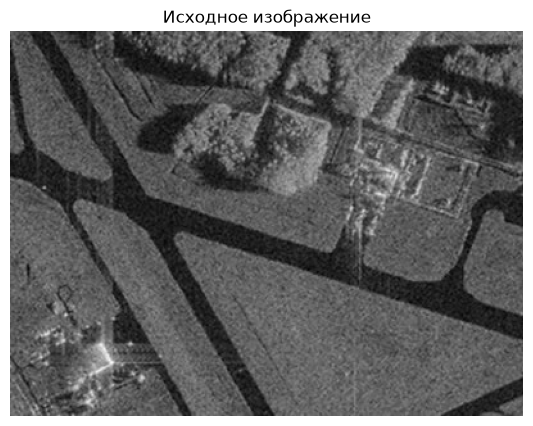

Результат загрузки изображения:
Размер изображения: (300, 400)


In [3]:
from pathlib import Path

image = cv2.imread(str(Path.home() / 'Desktop' / 'sar_1.jpg'))
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 5))
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')
plt.show()

print('Результат загрузки изображения:')
print('Размер изображения:', image_gray.shape)

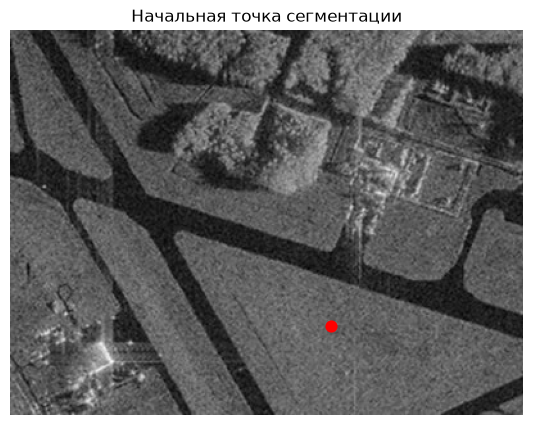

Начальная точка: (230, 250)


In [4]:
seed_point = (230, 250)

plt.figure(figsize=(8, 5))
plt.imshow(image_gray, cmap='gray')
plt.scatter(seed_point[1], seed_point[0], color='red', s=60)
plt.title('Начальная точка сегментации')
plt.axis('off')
plt.show()

print('Начальная точка:', seed_point)

In [49]:
from collections import deque

def grow_lawn(img, start, threshold):
    height, width = img.shape
    mask = np.zeros((height, width), dtype=np.uint8)

    queue = deque([start])
    mask[start] = 255

    total_brightness = float(img[start])
    pixel_count = 1

    while queue:
        y, x = queue.popleft()
        average = total_brightness / pixel_count

        for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            ny, nx = y + dy, x + dx

            if 0 <= ny < height and 0 <= nx < width:
                if mask[ny, nx] == 0:
                    brightness = float(img[ny, nx])

                    if abs(brightness - average) <= threshold:
                        mask[ny, nx] = 255
                        total_brightness += brightness
                        pixel_count += 1
                        queue.append((ny, nx))

    return mask

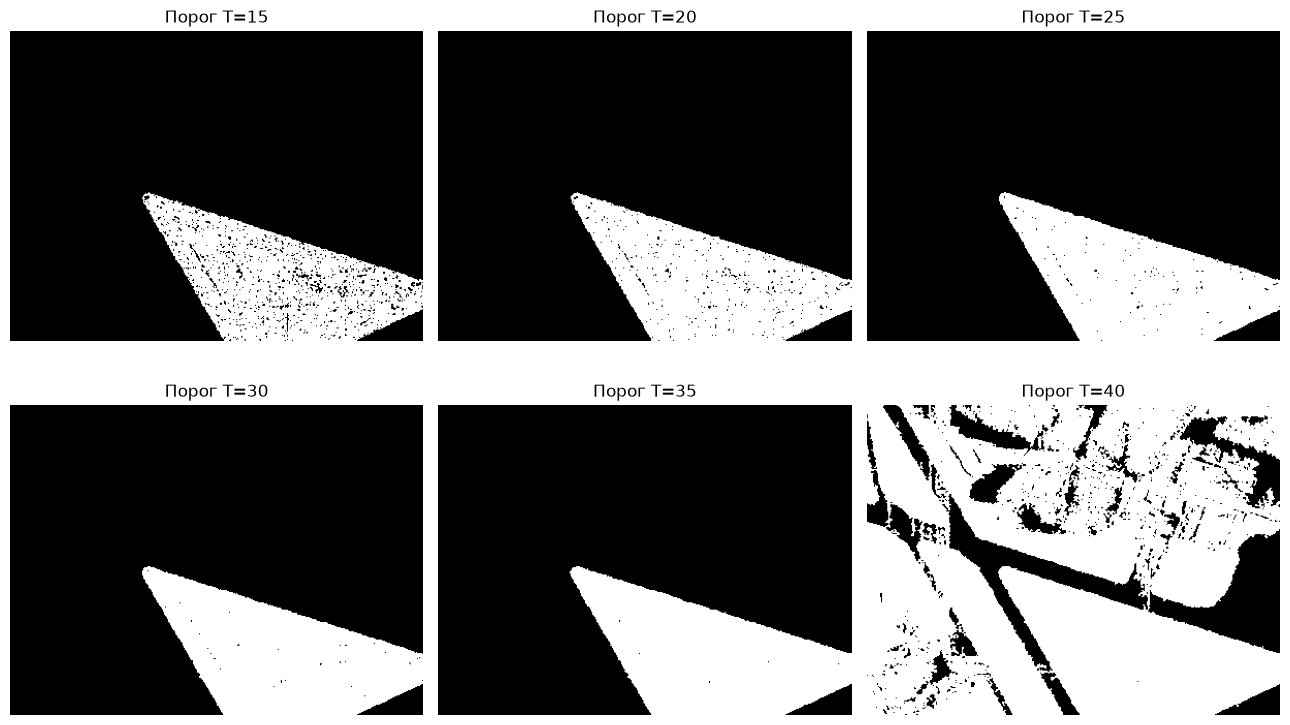

Количество выделенных пикселей:
T=15: 19392
T=20: 20837
T=25: 21348
T=30: 21566
T=35: 21688
T=40: 92916

Вывод: После сравнения шести вариантов я выбрала порог T=35.
При этом значении газон выделяется почти полностью, а лишние участки изображения не захватываются.


In [50]:
thresholds = [15, 20, 25, 30, 35, 40]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for ax, T in zip(axes.flat, thresholds):
    mask = grow_lawn(image_gray, seed_point, T)

    ax.imshow(mask, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Порог T={T}')
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Количество выделенных пикселей:')
for T in thresholds:
    mask = grow_lawn(image_gray, seed_point, T)
    print(f'T={T}: {np.count_nonzero(mask)}')

print()
print('Вывод: После сравнения шести вариантов я выбрала порог T=35.')
print('При этом значении газон выделяется почти полностью, а лишние участки изображения не захватываются.')

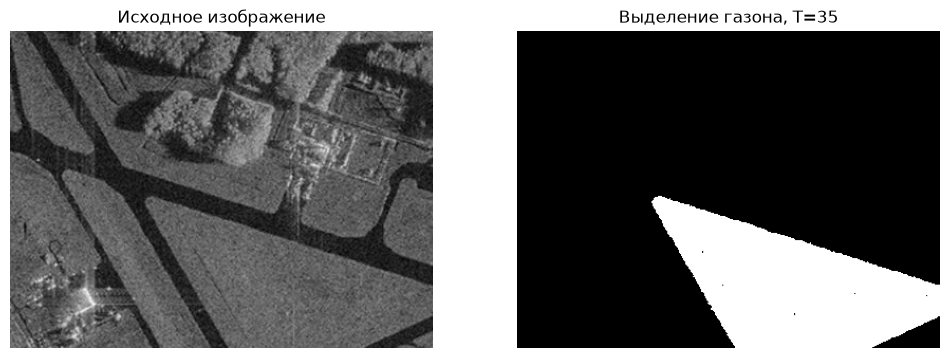

Результат сегментации:
Порог яркости: 35
Количество выделенных пикселей: 21688


In [9]:
lawn_mask = grow_lawn(image_gray, seed_point, 35)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lawn_mask, cmap='gray', vmin=0, vmax=255)
plt.title('Выделение газона, T=35')
plt.axis('off')

plt.show()

print('Результат сегментации:')
print('Порог яркости:', 35)
print('Количество выделенных пикселей:', np.sum(lawn_mask == 255))

In [14]:
def grow_lawn_neighbors(img, start, threshold):
    height, width = img.shape
    mask = np.zeros((height, width), dtype=np.uint8)

    queue = deque([start])
    mask[start] = 255

    while queue:
        y, x = queue.popleft()

        for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            ny, nx = y + dy, x + dx

            if 0 <= ny < height and 0 <= nx < width:
                if mask[ny, nx] == 0:
                    brightness = float(img[ny, nx])
                    neighbor_brightness = float(img[y, x])

                    if abs(brightness - neighbor_brightness) <= threshold:
                        mask[ny, nx] = 255
                        queue.append((ny, nx))

    return mask

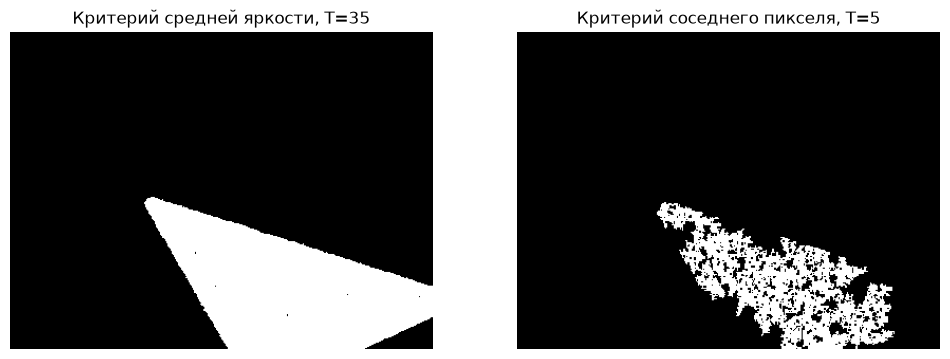

Сравнение двух критериев однородности:
Средняя яркость: 21688 пикселей
Соседний пиксель: 11101 пикселей
Вывод: Я сравнила два критерия разрастания региона: среднюю яркость и яркость соседнего пикселя.
При критерии средней яркости выделилось 21688 пикселей, а при критерии соседнего пикселя — 11101.
Первый способ лучше выделил участок газона, а второй оставил много пропусков.
Поэтому для этого изображения я считаю критерий средней яркости более подходящим.


In [16]:
mask_average = grow_lawn(image_gray, seed_point, 35)
mask_neighbors = grow_lawn_neighbors(image_gray, seed_point, 5)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(mask_average, cmap='gray', vmin=0, vmax=255)
plt.title('Критерий средней яркости, T=35')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask_neighbors, cmap='gray', vmin=0, vmax=255)
plt.title('Критерий соседнего пикселя, T=5')
plt.axis('off')

plt.show()

print('Сравнение двух критериев однородности:')
print('Средняя яркость:', np.count_nonzero(mask_average), 'пикселей')
print('Соседний пиксель:', np.count_nonzero(mask_neighbors), 'пикселей')

print('Вывод: Я сравнила два критерия разрастания региона: среднюю яркость и яркость соседнего пикселя.')
print('При критерии средней яркости выделилось 21688 пикселей, а при критерии соседнего пикселя — 11101.')
print('Первый способ лучше выделил участок газона, а второй оставил много пропусков.')
print('Поэтому для этого изображения я считаю критерий средней яркости более подходящим.')

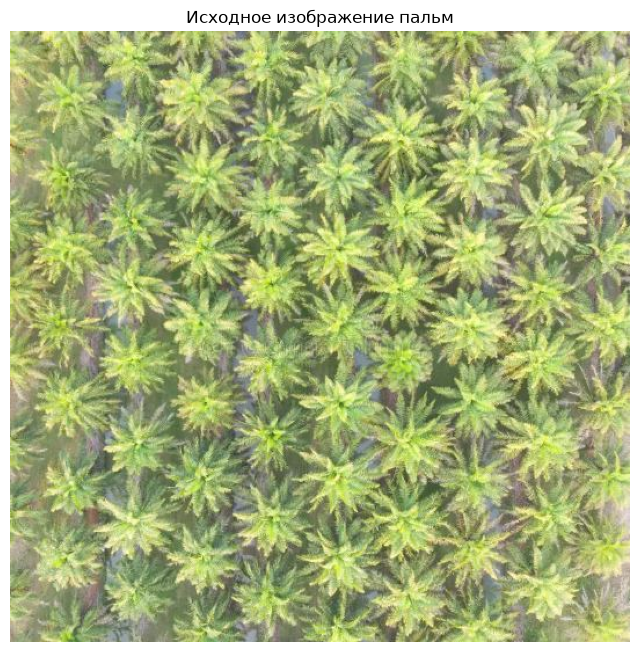

Результат загрузки изображения:
Размер изображения: (527, 535, 3)


In [17]:
from pathlib import Path

palms = cv2.imread(str(Path.home() / 'Desktop' / 'palm_1.JPG'))
palms_rgb = cv2.cvtColor(palms, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(palms_rgb)
plt.title('Исходное изображение пальм')
plt.axis('off')
plt.show()

print('Результат загрузки изображения:')
print('Размер изображения:', palms.shape)

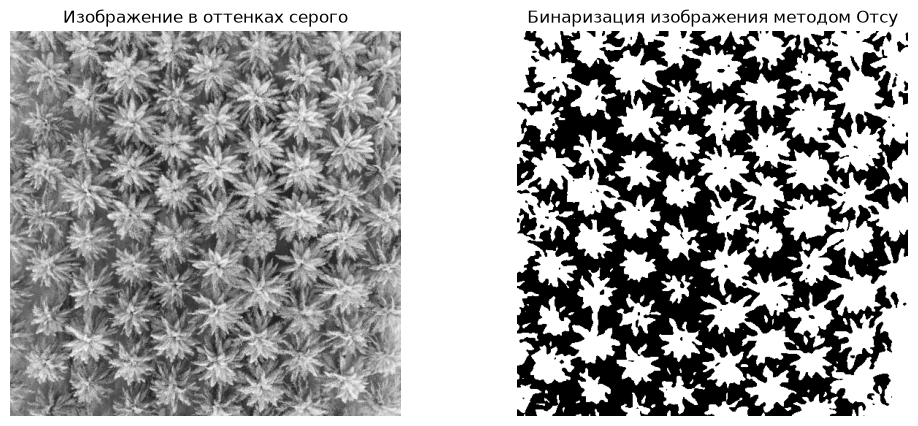

Количество выделенных пикселей: 142306


In [21]:
gray_palms = cv2.cvtColor(palms, cv2.COLOR_BGR2GRAY)

blurred_palms = cv2.GaussianBlur(gray_palms, (9, 9), 0)

_, bright_mask = cv2.threshold(
    blurred_palms, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_palms, cmap='gray')
plt.title('Изображение в оттенках серого')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(bright_mask, cmap='gray')
plt.title('Бинаризация изображения методом Отсу')
plt.axis('off')

plt.show()

print('Количество выделенных пикселей:', np.count_nonzero(bright_mask))

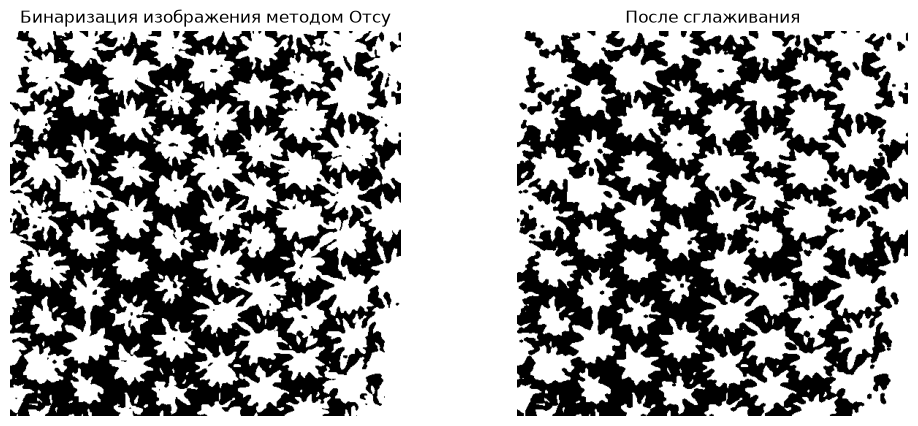

In [51]:
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

smooth_mask = cv2.morphologyEx(
    bright_mask,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(bright_mask, cmap='gray')
plt.title('Бинаризация изображения методом Отсу')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(smooth_mask, cmap='gray')
plt.title('После сглаживания')
plt.axis('off')

plt.show()

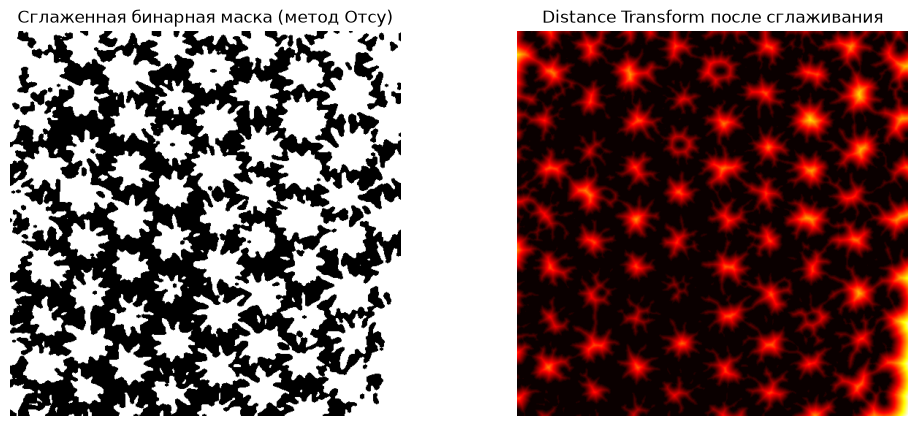

Максимальное расстояние: 34.159695


In [52]:
distance = cv2.distanceTransform(
    smooth_mask,
    cv2.DIST_L2,
    5
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(smooth_mask, cmap='gray')
plt.title('Сглаженная бинарная маска (метод Отсу)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(distance, cmap='hot')
plt.title('Distance Transform после сглаживания')
plt.axis('off')

plt.show()

print('Максимальное расстояние:', distance.max())

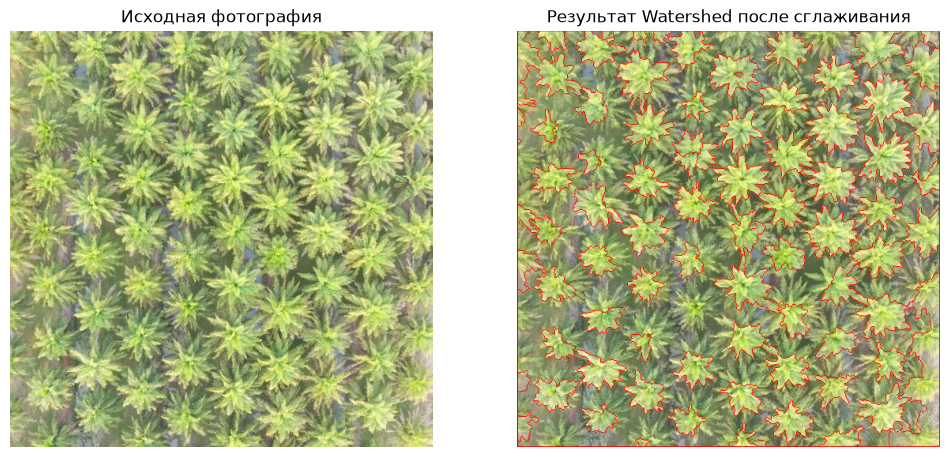

In [53]:
_, sure_fg = cv2.threshold(
    distance,
    0.25 * distance.max(),
    255,
    cv2.THRESH_BINARY
)

sure_fg = np.uint8(sure_fg)

num_labels, markers = cv2.connectedComponents(sure_fg)

markers = markers + 1

kernel = np.ones((3, 3), np.uint8)

sure_bg = cv2.dilate(
    smooth_mask,
    kernel,
    iterations=2
)

unknown = cv2.subtract(sure_bg, sure_fg)
markers[unknown == 255] = 0

watershed_markers = markers.copy()
cv2.watershed(palms.copy(), watershed_markers)

result_palms = palms_rgb.copy()
result_palms[watershed_markers == -1] = [255, 0, 0]

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(palms_rgb)
plt.title('Исходная фотография')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result_palms)
plt.title('Результат Watershed после сглаживания')
plt.axis('off')

plt.show()

In [54]:
palm_labels = np.unique(watershed_markers)
palm_count = np.sum(palm_labels > 1)

print('Предполагаемое количество пальм:', palm_count)

Предполагаемое количество пальм: 88
